In [21]:
from itertools import chain
import matplotlib.pyplot as plt
from nltk.lm import Laplace
from nltk.lm.preprocessing import padded_everygram_pipeline
from nltk.lm import Vocabulary
import numpy as np
import pandas as pd
from pathlib import Path
import re
from scipy.spatial.distance import jensenshannon
import seaborn as sns

In [22]:
# Find all CSV files in the data folder

DATA_PATH = Path("../data/Translated")
csv_files = sorted(DATA_PATH.glob("*.csv"))

print(f"Found {len(csv_files)} files:")
for file in csv_files:
    print(file.name)

Found 17 files:
Speeches_ALDE_Cleaned_Translated.csv
Speeches_CZ_Cleaned_Translated.csv
Speeches_DE_Cleaned_Translated.csv
Speeches_ECB_Cleaned_Translated.csv
Speeches_ECR_Cleaned_Translated.csv
Speeches_EC_Cleaned_Translated.csv
Speeches_EP_Cleaned_Translated.csv
Speeches_EUCouncil_Cleaned_Translated.csv
Speeches_FR_Cleaned_Translated.csv
Speeches_GR_Cleaned_Translated.csv
Speeches_IMF_Cleaned_Translated.csv
Speeches_IT_Cleaned_Translated.csv
Speeches_NL_Cleaned_Translated.csv
Speeches_PL_Cleaned_Translated.csv
Speeches_PO_Cleaned_Translated.csv
Speeches_SP_Cleaned_Translated.csv
Speeches_UK_Cleaned_Translated.csv


In [23]:
# Load all CSV files into DataFrame

ALL_COLUMNS = ["title", "date", "location", "speaker", "word_count", "raw", "raw_text", "original", "lang"]
USE_COLUMNS = ["title", "date", "location", "speaker", "raw"]

def clean_sentence(text: str) -> str:
    text = text.lower()
    text = re.sub(r"[^\w\s]", " ", text)
    text = re.sub(r"\s+", " ", text)
    return text.strip()

def split_sentences(text: str) -> list[str]:
    sentences = re.split(r"(?<=[.!?])\s+", text)
    return [clean_sentence(sentence) for sentence in sentences if sentence.strip()]

def load_speech_csv(path: Path) -> pd.DataFrame:
    nation = path.stem.split("_")[1]
    df = pd.read_csv(path, header=None, names=ALL_COLUMNS, usecols=USE_COLUMNS)
    df["nation"] = nation
    df["sentences"] = df["raw"].apply(split_sentences)
    return df

corpus = pd.concat([load_speech_csv(file) for file in csv_files], ignore_index=True)

expected = {file.stem.split("_")[1] for file in csv_files}
loaded = set(corpus["nation"].unique())
missing = expected - loaded
if missing:
    print(f"[WARNING] No speeches loaded for: {missing}")

print(f"Loaded {len(corpus)} speeches:")
corpus.head()

[WARNING] No speeches loaded for: {'IMF', 'UK'}
Loaded 6106 speeches:


,title,date,location,speaker,raw,nation,sentences
0,Rede von Guy Verhofstadt anläßlich des FDP Eur...,23-06-2013,European Parliament,Guy Verhofstadt,"Love Nadja, dear friends,Dear Sir or Madam,rea...",ALDE,[love nadja dear friends dear sir or madam rea...
1,Speech by Guy Verhofstadt - Intervention in pl...,05-02-2013,European Parliament,Guy Verhofstadt,Intervention Guy VerhofstadtNovember 21 2012Vi...,ALDE,[intervention guy verhofstadtnovember 21 2012v...
2,Speech by Guy Verhofstadt on the future of Europe,09-05-2012,European Parliament,Guy Verhofstadt,"Dear President, Dear colleagues,Let me paraphr...",ALDE,[dear president dear colleagues let me paraphr...
3,Speech by Guy Verhofstadt on PPV,12-03-2012,European Parliament,Guy Verhofstadt,"My group, President, for the initiative of Mr ...",ALDE,[my group president for the initiative of mr w...
4,Le Grand Direct de Guy Verhofstadt,07-03-2012,European Parliament,Guy Verhofstadt,Guy Verhofstadt Live dupuis RTL-TVI answering ...,ALDE,[guy verhofstadt live dupuis rtl tvi answering...


In [24]:
corpus.groupby("nation").size().sort_values(ascending=False).rename("speech_count")

nation
FR           1451
EP           1064
SP            996
IT            804
DE            580
GR            390
NL            260
CZ            234
EC            149
PO            133
ECB            18
EUCouncil      16
ALDE            6
PL              4
ECR             1
Name: speech_count, dtype: int64

In [25]:
# Exporting corpus for SRILM

output_directory = Path("../output/countries")
output_directory.mkdir(parents=True, exist_ok=True)

for nation, group in corpus.groupby("nation"):
    output_file = output_directory / f"{nation}.txt"

    with open(output_file, "w", encoding="utf-8") as output:
        for sentence_list in group["sentences"]:
            for sentence in sentence_list:
                output.write(sentence + "\n")

In [26]:
def tokenize_sentences(sentences: list[str]) -> list[list[str]]:
    return [sentence.split() for sentence in sentences if sentence.strip()]

corpus["tokens"] = corpus["sentences"].apply(tokenize_sentences)

In [27]:
all_tokens = chain.from_iterable(
    chain.from_iterable(token_lists) for token_lists in corpus["tokens"]
)
universal_vocab = Vocabulary(all_tokens, unk_cutoff=1)

print(f"Universal vocabulary size: {len(universal_vocab)}")

Universal vocabulary size: 62377


In [28]:
nation_unigram_models: dict[str, Laplace] = {}

for nation, group in corpus.groupby("nation"):
    nation_sentences = list(chain.from_iterable(group["tokens"]))
    train_data, _ = padded_everygram_pipeline(1, nation_sentences)

    model = Laplace(1, vocabulary=universal_vocab)
    model.fit(train_data)

    nation_unigram_models[nation] = model

print(f"Built {len(nation_unigram_models)} nation-level unigram models")

Built 15 nation-level unigram models


In [29]:
vocab_words = [word for word in universal_vocab if word not in ("<UNK>", "<s>", "</s>")]
vocab_index = {word: i for i, word in enumerate(vocab_words)}

def get_unigram_vector(model, vocab_words, vocab_index):
    counts = np.ones(len(vocab_words), dtype=np.float64)
    for word, count in model.counts[1].items():
        if word in vocab_index:
            counts[vocab_index[word]] += count
    return counts / counts.sum()

nations = sorted(nation_unigram_models.keys())

probability_matrix = np.vstack([
    get_unigram_vector(nation_unigram_models[nation], vocab_words, vocab_index)
    for nation in nations
])

print(f"Probability matrix shape: {probability_matrix.shape}")

Probability matrix shape: (15, 62376)


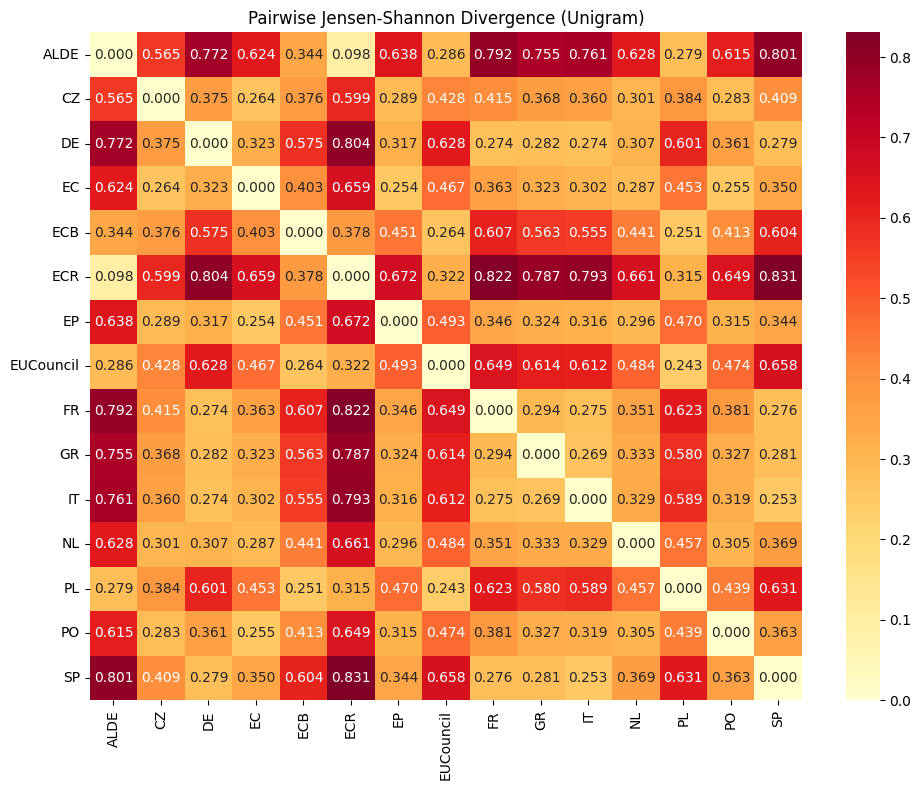

In [30]:
n = len(nations)
jsd_matrix = np.zeros((n, n))

for i in range(n):
    for j in range(i + 1, n):
        jsd_score = jensenshannon(probability_matrix[i], probability_matrix[j], base=2)
        jsd_matrix[i, j] = jsd_matrix[j, i] = jsd_score

jsd_df = pd.DataFrame(jsd_matrix, index=nations, columns=nations)

plt.figure(figsize=(10, 8))
sns.heatmap(jsd_df, annot=True, fmt=".3f", cmap="YlOrRd")
plt.title("Pairwise Jensen-Shannon Divergence (Unigram)")
plt.tight_layout()
plt.show()